## Load PCA Results ##

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path.cwd().parent

pca_dir = (
    project_dir
    / "models"
    / "pca"
    / "2015-2016"
)

scores = pd.read_parquet(pca_dir / "player_scores.parquet")
variance = pd.read_parquet(pca_dir / "explained_variance.parquet")
loadings = pd.read_parquet(pca_dir / "loadings.parquet")

In [25]:
print(scores.shape)
print(loadings.shape)

display(loadings.head())
display(scores.head())

(1560, 32)
(21, 22)


,feature,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,...,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21
0,goals_per90,0.226093,0.239791,-0.153385,0.279293,-0.138427,0.026996,0.277413,-0.281805,-0.199698,...,-0.074601,-0.234521,0.311148,0.378869,-0.244322,0.186048,-0.339170,-0.206570,-0.009156,0.011349
1,xG_per90,0.239180,0.254228,-0.196019,0.237667,-0.153701,-0.000256,0.197116,-0.192140,-0.105719,...,-0.034112,0.001443,-0.057318,-0.051606,0.113094,-0.084680,0.512146,0.609171,-0.014649,-0.001529
2,shots_per90,0.302616,0.189904,-0.118055,0.149096,-0.080866,-0.026814,0.101344,-0.204248,-0.039658,...,0.092288,0.064316,-0.453456,-0.501233,0.205714,-0.133071,-0.149269,-0.445790,-0.008745,-0.061665
3,xA_per90,0.304429,0.064359,0.165441,0.063941,-0.084384,0.411783,-0.115963,0.032878,0.130879,...,0.210299,-0.063372,0.220129,0.177160,0.235466,0.094862,0.455427,-0.372238,-0.037780,-0.012674
4,shot_assists_per90,0.313483,0.018146,0.183331,0.038200,-0.148740,0.342478,-0.166080,-0.021800,0.090864,...,0.131968,0.017388,0.029123,-0.161586,-0.098840,-0.116493,-0.531067,0.450223,0.058958,-0.024018


,competition_id,competition,season_id,season,player_id,player,team_ids,teams,minutes_played,primary_position,...,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21
0,11,La Liga,27,2015-2016,3023,Yuri Berchiche Izeta,[210],[Real Sociedad],1924.300817,Left Back,...,-0.921706,0.182168,-0.780735,0.523046,-0.001968,-0.499714,-0.044920,0.015813,-0.010728,-0.076287
1,11,La Liga,27,2015-2016,3063,Danilo Luiz da Silva,[220],[Real Madrid],2126.004433,Right Back,...,-0.584293,-0.353355,-0.449856,0.677308,0.587533,0.095248,-0.169478,-0.146184,-0.114571,0.019726
2,11,La Liga,27,2015-2016,3160,Rene Krhin,[1049],[Granada],1516.129717,Right Defensive Midfield,...,-0.407461,0.026383,-0.034409,-0.146552,-0.248204,0.024412,-0.026611,0.053879,-0.201708,-0.154853
3,11,La Liga,27,2015-2016,3240,Mathew Ryan,[207],[Valencia],762.405733,Goalkeeper,...,-0.452691,-0.287455,0.130257,-0.067405,-0.280641,-0.862147,0.243161,-0.213142,0.089622,0.287928
4,11,La Liga,27,2015-2016,3253,Adil Rami,[213],[Sevilla],2529.217267,Right Center Back,...,0.302839,0.124376,-0.170783,-0.046307,0.206466,-0.046513,0.080538,0.092671,0.038741,0.055393


## Explained variance ##

In [26]:
display(variance)

,component,explained_variance,explained_variance_ratio,cumulative_explained_variance_ratio
0,PC1,6.726708,0.320114,0.320114
1,PC2,4.619688,0.219844,0.539958
2,PC3,2.805849,0.133526,0.673484
3,PC4,1.478798,0.070374,0.743858
4,PC5,0.982790,0.046770,0.790628
5,PC6,0.849248,0.040414,0.831042
6,PC7,0.603344,0.028712,0.859755
7,PC8,0.508534,0.024200,0.883955
8,PC9,0.417920,0.019888,0.903843
9,PC10,0.384420,0.018294,0.922137


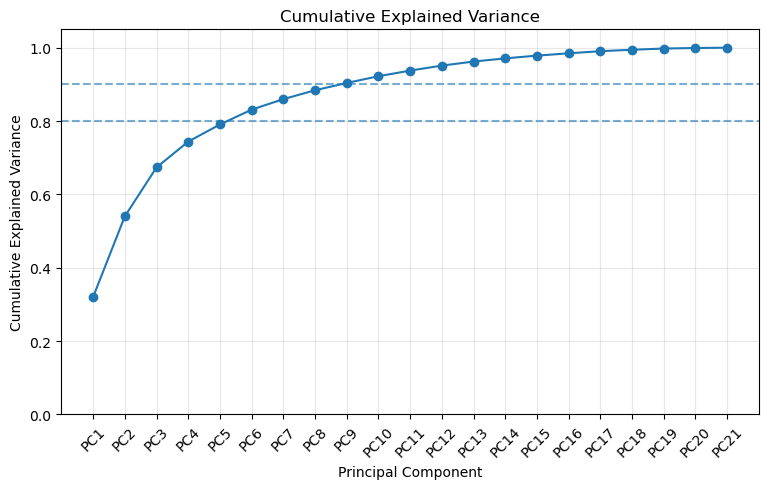

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    variance["component"],
    variance["cumulative_explained_variance_ratio"],
    marker="o"
)

plt.axhline(0.80, linestyle="--", alpha=0.6)
plt.axhline(0.90, linestyle="--", alpha=0.6)

plt.xlabel("Principal Component")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.xticks(rotation=45)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)

plt.show()

## Inspect component loadings ##

In [28]:
def inspect_component(component, n=10):
    component_loadings = (
        loadings[["feature", component]]
        .assign(abs_loading=lambda df: df[component].abs())
        .sort_values("abs_loading", ascending=False)
    )

    return component_loadings.head(n)

In [29]:
inspect_component("PC1")

,feature,PC1,abs_loading
8,dribbles_attempted_per90,0.331655,0.331655
9,dribbles_completed_per90,0.320923,0.320923
4,shot_assists_per90,0.313483,0.313483
3,xA_per90,0.304429,0.304429
11,progressive_carries_per90,0.303605,0.303605
2,shots_per90,0.302616,0.302616
20,poss_won_final_third_per90,0.258431,0.258431
18,pressures_per90,0.250488,0.250488
1,xG_per90,0.239180,0.239180
0,goals_per90,0.226093,0.226093


In [30]:
inspect_component("PC2")

,feature,PC2,abs_loading
15,tackles_won_per90,-0.377538,0.377538
6,passes_completed_per90,-0.350405,0.350405
13,interceptions_won_per90,-0.341067,0.341067
16,blocks_per90,-0.316928,0.316928
7,pass_completion_pct,-0.300470,0.300470
10,carries_per90,-0.275509,0.275509
1,xG_per90,0.254228,0.254228
0,goals_per90,0.239791,0.239791
18,pressures_per90,-0.226412,0.226412
12,ball_recoveries_won_per90,-0.202569,0.202569


In [31]:
inspect_component("PC3")

,feature,PC3,abs_loading
5,progressive_passes_per90,0.452641,0.452641
14,duels_per90,-0.424605,0.424605
19,fouls_per90,-0.318893,0.318893
12,ball_recoveries_won_per90,0.291032,0.291032
10,carries_per90,0.238716,0.238716
6,passes_completed_per90,0.226196,0.226196
1,xG_per90,-0.196019,0.196019
18,pressures_per90,-0.192994,0.192994
16,blocks_per90,-0.189169,0.189169
4,shot_assists_per90,0.183331,0.183331


In [32]:
inspect_component("PC4")

,feature,PC4,abs_loading
7,pass_completion_pct,0.530845,0.530845
6,passes_completed_per90,0.347012,0.347012
12,ball_recoveries_won_per90,-0.302024,0.302024
17,clearances_per90,0.283095,0.283095
0,goals_per90,0.279293,0.279293
10,carries_per90,0.273290,0.273290
1,xG_per90,0.237667,0.237667
19,fouls_per90,-0.202986,0.202986
20,poss_won_final_third_per90,-0.193497,0.193497
18,pressures_per90,-0.188043,0.188043


In [33]:
inspect_component("PC5")

,feature,PC5,abs_loading
9,dribbles_completed_per90,0.403849,0.403849
8,dribbles_attempted_per90,0.401240,0.401240
11,progressive_carries_per90,0.401115,0.401115
17,clearances_per90,0.334042,0.334042
6,passes_completed_per90,-0.249324,0.249324
13,interceptions_won_per90,0.235352,0.235352
16,blocks_per90,0.228862,0.228862
20,poss_won_final_third_per90,-0.210191,0.210191
5,progressive_passes_per90,-0.186937,0.186937
1,xG_per90,-0.153701,0.153701


In [34]:
inspect_component("PC6")

,feature,PC6,abs_loading
12,ball_recoveries_won_per90,-0.414998,0.414998
3,xA_per90,0.411783,0.411783
5,progressive_passes_per90,0.395312,0.395312
4,shot_assists_per90,0.342478,0.342478
16,blocks_per90,0.341769,0.341769
7,pass_completion_pct,-0.289095,0.289095
17,clearances_per90,0.288407,0.288407
9,dribbles_completed_per90,-0.162799,0.162799
13,interceptions_won_per90,0.135021,0.135021
8,dribbles_attempted_per90,-0.118832,0.118832


In [35]:
inspect_component("PC7")

,feature,PC7,abs_loading
13,interceptions_won_per90,0.596004,0.596004
20,poss_won_final_third_per90,0.449306,0.449306
0,goals_per90,0.277413,0.277413
18,pressures_per90,-0.249445,0.249445
19,fouls_per90,-0.243684,0.243684
16,blocks_per90,-0.233984,0.233984
1,xG_per90,0.197116,0.197116
4,shot_assists_per90,-0.166080,0.166080
12,ball_recoveries_won_per90,0.165483,0.165483
15,tackles_won_per90,0.163433,0.163433


In [36]:
inspect_component("PC8")

,feature,PC8,abs_loading
20,poss_won_final_third_per90,0.668713,0.668713
12,ball_recoveries_won_per90,-0.432526,0.432526
0,goals_per90,-0.281805,0.281805
13,interceptions_won_per90,-0.222308,0.222308
5,progressive_passes_per90,-0.212243,0.212243
2,shots_per90,-0.204248,0.204248
1,xG_per90,-0.192140,0.192140
19,fouls_per90,-0.191316,0.191316
7,pass_completion_pct,0.174222,0.174222
16,blocks_per90,-0.133645,0.133645


## Plotting component loadings ##

In [37]:
def plot_component_loadings(component):
    component_loadings = (
        loadings[["feature", component]]
        .sort_values(component)
    )

    plt.figure(figsize=(8, 7))

    plt.barh(
        component_loadings["feature"],
        component_loadings[component]
    )

    plt.axvline(0, linewidth=1)
    plt.xlabel("Loading")
    plt.ylabel("Feature")
    plt.title(f"{component} Loadings")

    plt.tight_layout()
    plt.show()

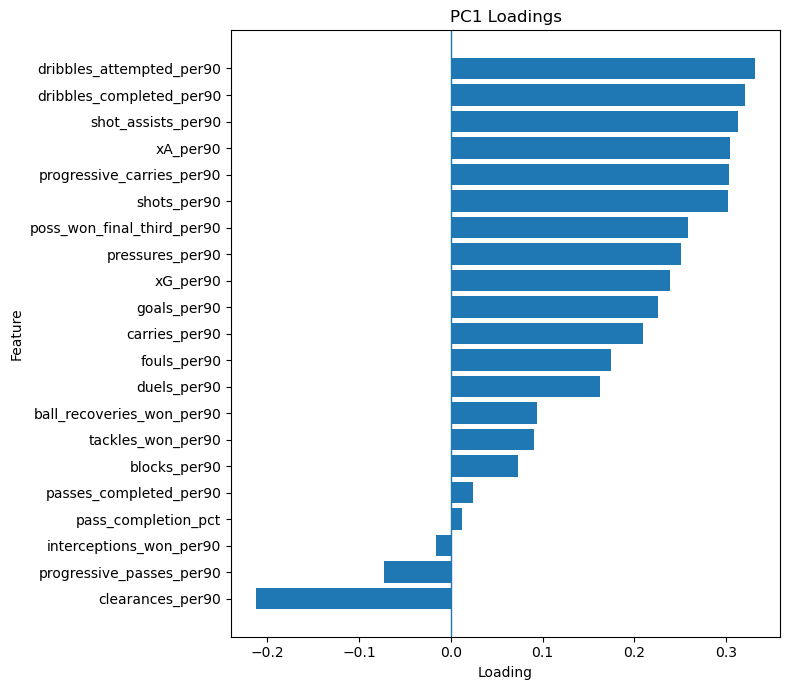

In [38]:
plot_component_loadings("PC1")

### Thoughts: ###
Direct attacking threat, particularly through carries

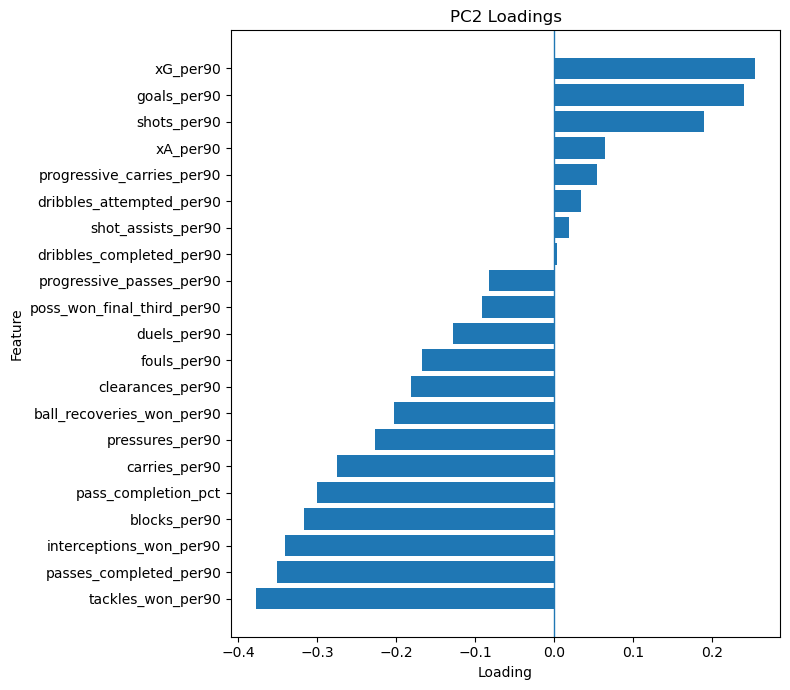

In [39]:
plot_component_loadings("PC2")

### Thoughts: ###
Goal-scoring intent <--> More defensive

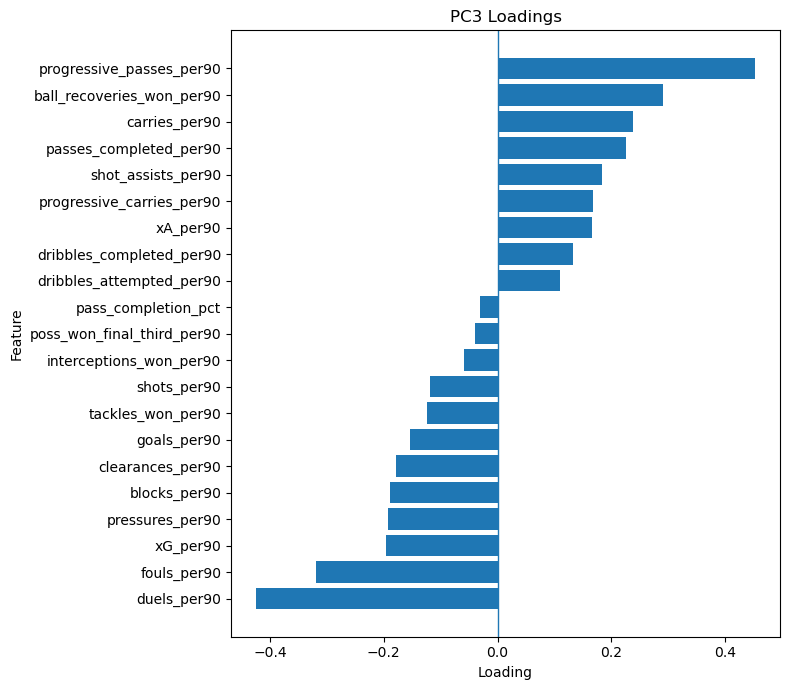

In [40]:
plot_component_loadings("PC3")

### Thoughts: ###
Link up play rather than physical involvement

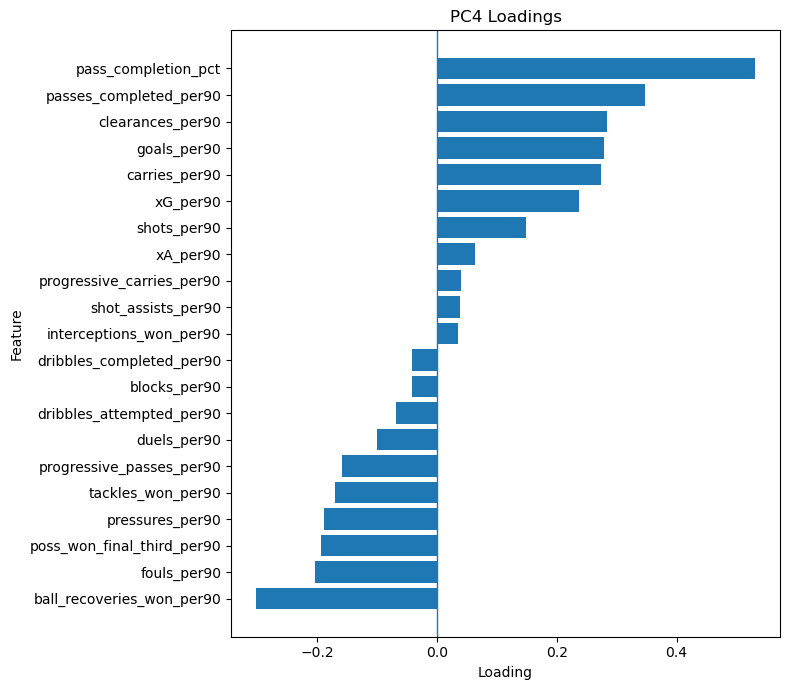

In [47]:
plot_component_loadings("PC4")

## Mapping PC to Players ##

In [41]:
def component_extremes(component, n=10):
    columns = [
        "player",
        "teams",
        "primary_position",
        "position_group",
        component,
    ]

    highest = scores.nlargest(n, component)[columns]
    lowest = scores.nsmallest(n, component)[columns]

    return highest, lowest

In [42]:
highest, lowest = component_extremes("PC1")

display(highest)
display(lowest)

,player,teams,primary_position,position_group,PC1
16,Neymar da Silva Santos Junior,[Barcelona],Left Wing,Outside Midfielder,9.436652
47,Lionel Andrés Messi Cuccittini,[Barcelona],Right Wing,Outside Midfielder,9.333970
525,Sofiane Boufal,[Lille],Left Wing,Outside Midfielder,8.605694
59,Yannick Ferreira Carrasco,[Atlético Madrid],Left Midfield,Outside Midfielder,7.255995
868,Alexis Alejandro Sánchez Sánchez,[Arsenal],Left Wing,Outside Midfielder,6.701632
15,Jesé Rodríguez Ruiz,[Real Madrid],Right Wing,Outside Midfielder,6.580368
499,Rachid Ghezzal,[Lyon],Right Wing,Outside Midfielder,6.324966
1220,Paulo Bruno Exequiel Dybala,[Juventus],Right Center Forward,Forward,6.182932
1209,Dries Mertens,[Napoli],Left Wing,Outside Midfielder,6.165916
76,Ángel Martín Correa,[Atlético Madrid],Right Center Forward,Forward,6.124104


,player,teams,primary_position,position_group,PC1
996,Fraser Forster,[Southampton],Goalkeeper,Goalkeeper,-4.716552
944,Alex McCarthy,[Crystal Palace],Goalkeeper,Goalkeeper,-4.709156
1003,Ben Foster,[West Bromwich Albion],Goalkeeper,Goalkeeper,-4.679027
403,Rémy Vercoutre,"[Stade Malherbe Caen, Caen]",Goalkeeper,Goalkeeper,-4.670979
387,Manuel Fernández Muñíz,[RC Deportivo La Coruña],Goalkeeper,Goalkeeper,-4.666626
817,Rob Elliot,[Newcastle United],Goalkeeper,Goalkeeper,-4.640502
957,Karl Darlow,[Newcastle United],Goalkeeper,Goalkeeper,-4.639202
1511,Nicola Leali,[Frosinone],Goalkeeper,Goalkeeper,-4.636426
1033,Glyn Oliver Myhill,[West Bromwich Albion],Goalkeeper,Goalkeeper,-4.627336
1114,Mark Bunn,[Aston Villa],Goalkeeper,Goalkeeper,-4.620096


In [43]:
highest, lowest = component_extremes("PC2")

display(highest)
display(lowest)

,player,teams,primary_position,position_group,PC2
33,Cristiano Ronaldo dos Santos Aveiro,[Real Madrid],Left Wing,Outside Midfielder,6.862358
38,Luis Alberto Suárez Díaz,[Barcelona],Center Forward,Forward,6.103839
1197,Gonzalo Gerardo Higuaín,[Napoli],Center Forward,Forward,5.930109
306,Karim Benzema,[Real Madrid],Center Forward,Forward,5.774415
1185,Manolo Gabbiadini,[Napoli],Center Forward,Forward,5.646346
527,Zlatan Ibrahimović,[Paris Saint-Germain],Center Forward,Forward,5.623611
142,Imanol Agirretxe Arruti,[Real Sociedad],Center Forward,Forward,5.596012
1468,Luca Toni,[Hellas Verona],Center Forward,Forward,4.949382
913,Daniel Andre Sturridge,[Liverpool],Center Forward,Forward,4.856733
1090,Jamie Vardy,[Leicester City],Left Center Forward,Forward,4.853969


,player,teams,primary_position,position_group,PC2
453,Marco Verratti,[Paris Saint-Germain],Right Center Midfield,Center Midfielder,-5.733828
50,Carlos Henrique Casimiro,[Real Madrid],Center Defensive Midfield,Center Midfielder,-5.617000
1279,Jorge Luiz Frello Filho,[Napoli],Center Defensive Midfield,Center Midfielder,-5.430189
873,Francis Joseph Coquelin,[Arsenal],Right Defensive Midfield,Center Midfielder,-5.239112
305,Augusto Matías Fernández,"[Atlético Madrid, Celta Vigo]",Center Defensive Midfield,Center Midfielder,-4.973600
428,Adrien Rabiot,[Paris Saint-Germain],Left Center Midfield,Center Midfielder,-4.973430
992,N''Golo Kanté,[Leicester City],Left Defensive Midfield,Center Midfielder,-4.956289
1164,Cheik Ismaël Tioté,[Newcastle United],Right Center Midfield,Center Midfielder,-4.837982
247,Sebastián Carlos Cristóforo Pepe,[Sevilla],Left Defensive Midfield,Center Midfielder,-4.706125
872,Idrissa Gana Gueye,[Aston Villa],Left Center Midfield,Center Midfielder,-4.675518


In [44]:
highest, lowest = component_extremes("PC3")

display(highest)
display(lowest)

,player,teams,primary_position,position_group,PC3
418,Ángel Fabián Di María Hernández,[Paris Saint-Germain],Right Wing,Outside Midfielder,6.178052
899,Mesut Özil,[Arsenal],Center Attacking Midfield,Attacking Midfielder,5.388360
1097,Santiago Cazorla González,[Arsenal],Left Defensive Midfield,Center Midfielder,5.200637
559,Javier Matías Pastore,[Paris Saint-Germain],Right Center Midfield,Center Midfielder,4.969184
453,Marco Verratti,[Paris Saint-Germain],Right Center Midfield,Center Midfielder,4.950840
47,Lionel Andrés Messi Cuccittini,[Barcelona],Right Wing,Outside Midfielder,4.696939
897,Dimitri Payet,[West Ham United],Left Wing,Outside Midfielder,4.644666
945,Eden Hazard,[Chelsea],Left Wing,Outside Midfielder,4.480421
975,Gerard Deulofeu Lázaro,[Everton],Right Wing,Outside Midfielder,4.465119
609,Juan Fernando Quintero Paniagua,[Rennes],Center Attacking Midfield,Attacking Midfielder,4.456647


,player,teams,primary_position,position_group,PC3
1381,Leonardo Pavoletti,[Genoa],Center Forward,Forward,-4.585715
967,José Leonardo Ulloa,[Leicester City],Right Center Forward,Forward,-4.416269
1005,Aleksandar Mitrović,[Newcastle United],Center Forward,Forward,-4.006215
1537,Giulio Migliaccio,[Atalanta],Right Center Midfield,Center Midfielder,-3.979846
791,Evaeverson Lemos da Silva Brandão,[Bastia],Center Forward,Forward,-3.976906
632,Thiago Xavier Rodrigues Corrêa,[Troyes],Center Defensive Midfield,Center Midfielder,-3.900401
384,Ricky van Wolfswinkel,[Real Betis],Right Center Forward,Forward,-3.846821
1292,Roberto Inglese,[Chievo],Right Center Forward,Forward,-3.757182
809,Glenn Murray,"[AFC Bournemouth, Crystal Palace]",Center Forward,Forward,-3.721069
1386,Maximiliano Gastón López,[Torino],Right Center Forward,Forward,-3.676776


In [46]:
highest, lowest = component_extremes("PC4")

display(highest)
display(lowest)

,player,teams,primary_position,position_group,PC4
527,Zlatan Ibrahimović,[Paris Saint-Germain],Center Forward,Forward,5.398403
33,Cristiano Ronaldo dos Santos Aveiro,[Real Madrid],Left Wing,Outside Midfielder,4.976510
47,Lionel Andrés Messi Cuccittini,[Barcelona],Right Wing,Outside Midfielder,4.967793
306,Karim Benzema,[Real Madrid],Center Forward,Forward,4.236956
1197,Gonzalo Gerardo Higuaín,[Napoli],Center Forward,Forward,4.120341
487,Thiago Emiliano da Silva,[Paris Saint-Germain],Right Center Back,Center Back,3.865563
16,Neymar da Silva Santos Junior,[Barcelona],Left Wing,Outside Midfielder,3.708484
552,Thiago Motta,[Paris Saint-Germain],Center Defensive Midfield,Center Midfielder,3.673929
38,Luis Alberto Suárez Díaz,[Barcelona],Center Forward,Forward,3.562874
91,Gareth Frank Bale,[Real Madrid],Right Wing,Outside Midfielder,3.466070


,player,teams,primary_position,position_group,PC4
1507,Marco Crimi,"[Carpi, Bologna]",Right Center Midfield,Center Midfielder,-4.110365
496,Marcus Coco,[Guingamp],Right Midfield,Outside Midfielder,-3.912220
980,Kasper Schmeichel,[Leicester City],Goalkeeper,Goalkeeper,-3.025934
1502,Lorenzo Lollo,[Carpi],Center Attacking Midfield,Attacking Midfielder,-3.022842
465,Renaud Cohade,[Saint-Étienne],Left Center Midfield,Center Midfielder,-2.975976
1469,Mirko Gori,[Frosinone],Center Defensive Midfield,Center Midfielder,-2.898140
1103,Jan Kirchhoff,[Sunderland],Center Defensive Midfield,Center Midfielder,-2.819517
275,Asier Riesgo Unamuno,[Eibar],Goalkeeper,Goalkeeper,-2.813516
1406,Vid Belec,[Carpi],Goalkeeper,Goalkeeper,-2.769532
156,Gonzalo Escalante,[Eibar],Right Defensive Midfield,Center Midfielder,-2.767920


In [48]:
highest, lowest = component_extremes("PC5")

display(highest)
display(lowest)

,player,teams,primary_position,position_group,PC5
902,Wilfried Zaha,[Crystal Palace],Right Midfield,Outside Midfielder,4.062877
369,Abdoul Karim Yoda,[Getafe],Left Back,Fullback,3.948060
1069,Modou Barrow,[Swansea City],Right Wing,Outside Midfielder,3.835947
11,Charly Musonda Junior,[Real Betis],Left Midfield,Outside Midfielder,3.688609
1055,Jefferson Antonio Montero Vite,[Swansea City],Left Wing,Outside Midfielder,3.374350
314,Alhassane Bangoura,[Rayo Vallecano],Right Wing,Outside Midfielder,3.236684
842,Andros Townsend,"[Tottenham Hotspur, Newcastle United]",Right Wing,Outside Midfielder,3.176052
950,Jordon Ibe,[Liverpool],Right Wing,Outside Midfielder,3.086208
262,Armindo Tué Na Bangna,[Real Sociedad],Left Wing,Outside Midfielder,3.046569
268,José Ignacio Peleteiro Ramallo,[Eibar],Left Midfield,Outside Midfielder,3.000721


,player,teams,primary_position,position_group,PC5
1279,Jorge Luiz Frello Filho,[Napoli],Center Defensive Midfield,Center Midfielder,-3.539104
527,Zlatan Ibrahimović,[Paris Saint-Germain],Center Forward,Forward,-3.114960
891,Francesc Fàbregas i Soler,[Chelsea],Right Defensive Midfield,Center Midfielder,-3.051300
552,Thiago Motta,[Paris Saint-Germain],Center Defensive Midfield,Center Midfielder,-2.914458
723,Abdelaziz Barrada,"[Olympique de Marseille, Marseille]",Left Center Midfield,Center Midfielder,-2.629089
53,Toni Kroos,[Real Madrid],Center Defensive Midfield,Center Midfielder,-2.594504
453,Marco Verratti,[Paris Saint-Germain],Right Center Midfield,Center Midfielder,-2.551297
971,Kelechi Promise Iheanacho,[Manchester City],Center Forward,Forward,-2.454335
1245,Miralem Pjanić,[AS Roma],Right Center Midfield,Center Midfielder,-2.403242
465,Renaud Cohade,[Saint-Étienne],Left Center Midfield,Center Midfielder,-2.315849


In [49]:
highest, lowest = component_extremes("PC6")

display(highest)
display(lowest)

,player,teams,primary_position,position_group,PC6
977,Christian Fuchs,[Leicester City],Left Back,Fullback,4.046961
418,Ángel Fabián Di María Hernández,[Paris Saint-Germain],Right Wing,Outside Midfielder,4.005384
1405,Daniel Pavlovic,[Frosinone],Left Back,Fullback,3.731173
723,Abdelaziz Barrada,"[Olympique de Marseille, Marseille]",Left Center Midfield,Center Midfielder,3.614940
899,Mesut Özil,[Arsenal],Center Attacking Midfield,Attacking Midfielder,3.121352
812,Kevin De Bruyne,[Manchester City],Right Wing,Outside Midfielder,2.988557
63,James David Rodríguez Rubio,[Real Madrid],Left Center Midfield,Center Midfielder,2.943582
982,Dušan Tadić,[Southampton],Left Wing,Outside Midfielder,2.821851
319,José Antonio Reyes Calderón,[Sevilla],Right Wing,Outside Midfielder,2.785298
467,Almamy Touré,[AS Monaco],Right Back,Fullback,2.719241


,player,teams,primary_position,position_group,PC6
1143,Alexandre Dimitri Song-Billong,[West Ham United],Center Defensive Midfield,Center Midfielder,-3.144916
457,Lassana Diarra,"[Olympique de Marseille, Marseille]",Left Defensive Midfield,Center Midfielder,-2.910168
581,Nampalys Mendy,[OGC Nice],Center Defensive Midfield,Center Midfielder,-2.848605
1010,Gilbert Gianelli Imbula Wanga,[Stoke City],Left Defensive Midfield,Center Midfielder,-2.749365
670,Seko Fofana,[Bastia],Left Defensive Midfield,Center Midfielder,-2.613451
12,Roque Mesa Quevedo,[Las Palmas],Right Defensive Midfield,Center Midfielder,-2.607990
1174,Assane Dioussé El Hadji,[Empoli],Center Defensive Midfield,Center Midfielder,-2.520280
290,Wanderson Maciel Sousa Campos,[Getafe],Left Wing,Outside Midfielder,-2.407102
1227,Geoffrey Kondogbia,[Inter Milan],Left Center Midfield,Center Midfielder,-2.397868
428,Adrien Rabiot,[Paris Saint-Germain],Left Center Midfield,Center Midfielder,-2.352796


## Plotting PC Distributions ##

In [50]:
def plot_players(component_x, component_y, player_names=None):
    plt.figure(figsize=(10, 7))

    plt.scatter(
        scores[component_x],
        scores[component_y],
        alpha=0.4
    )

    if player_names:
        selected = scores[
            scores["player"].isin(player_names)
        ]

        for _, row in selected.iterrows():
            plt.annotate(
                row["player"],
                (row[component_x], row[component_y]),
                xytext=(5, 5),
                textcoords="offset points",
            )

    plt.xlabel(component_x)
    plt.ylabel(component_y)
    plt.title(f"{component_x} vs {component_y}")

    plt.axhline(0, linewidth=0.8, alpha=0.4)
    plt.axvline(0, linewidth=0.8, alpha=0.4)

    plt.show()

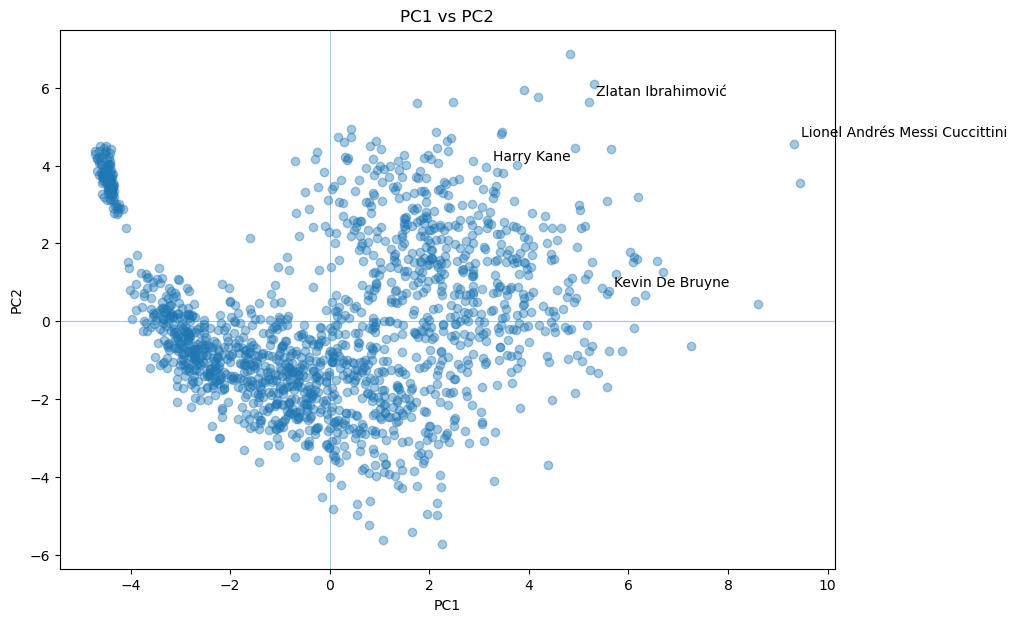

In [55]:
plot_players(
    "PC1",
    "PC2",
    [
        "Kevin De Bruyne",
        "Harry Kane",
        "Lionel Andrés Messi Cuccittini",
        "Zlatan Ibrahimović"
    ]
)

## Compare PC by position ##

In [56]:
scores.groupby("position_group")[
    ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7", "PC8"]
].mean().round(2)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
position_group,,,,,,,,
Attacking Midfielder,2.62,0.12,0.61,0.02,-0.39,-0.12,-0.25,0.01
Center Back,-2.79,-0.67,-0.72,1.12,0.65,0.17,0.07,-0.02
Center Midfielder,0.56,-1.99,-0.05,-0.25,-0.67,-0.51,-0.05,-0.13
Forward,1.87,2.92,-2.11,0.37,-0.60,-0.10,0.00,-0.04
Fullback,-0.76,-1.21,0.39,-0.20,0.24,0.64,-0.01,0.03
Goalkeeper,-4.45,3.65,2.54,-1.45,-0.60,-0.63,0.26,0.05
Outside Midfielder,2.90,0.79,0.69,-0.29,0.70,0.11,-0.05,0.15


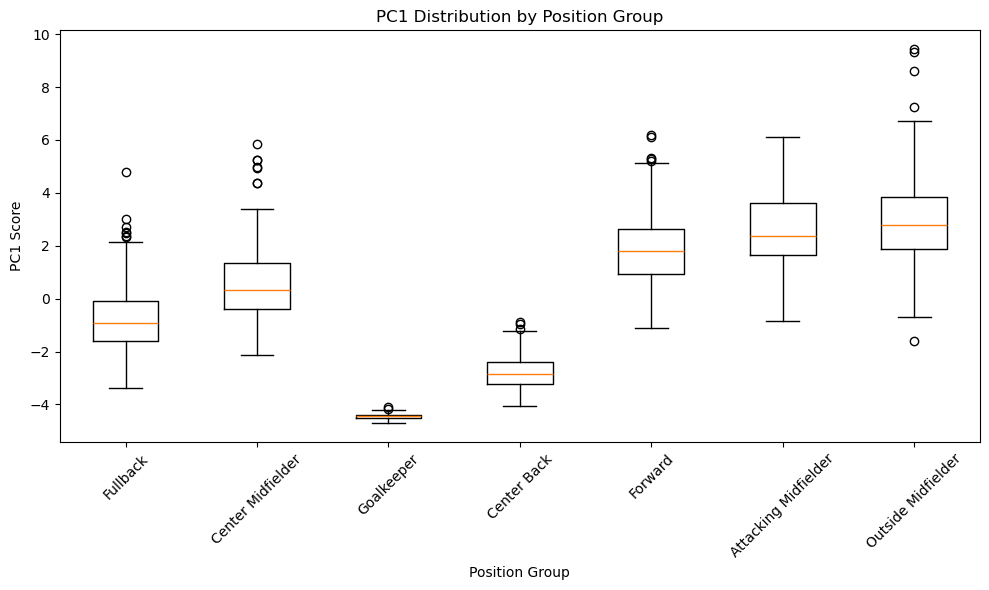

In [57]:
position_groups = scores["position_group"].dropna().unique()

plt.figure(figsize=(10, 6))

data = [
    scores.loc[
        scores["position_group"] == position,
        "PC1"
    ]
    for position in position_groups
]

plt.boxplot(
    data,
    tick_labels=position_groups,
)

plt.xlabel("Position Group")
plt.ylabel("PC1 Score")
plt.title("PC1 Distribution by Position Group")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

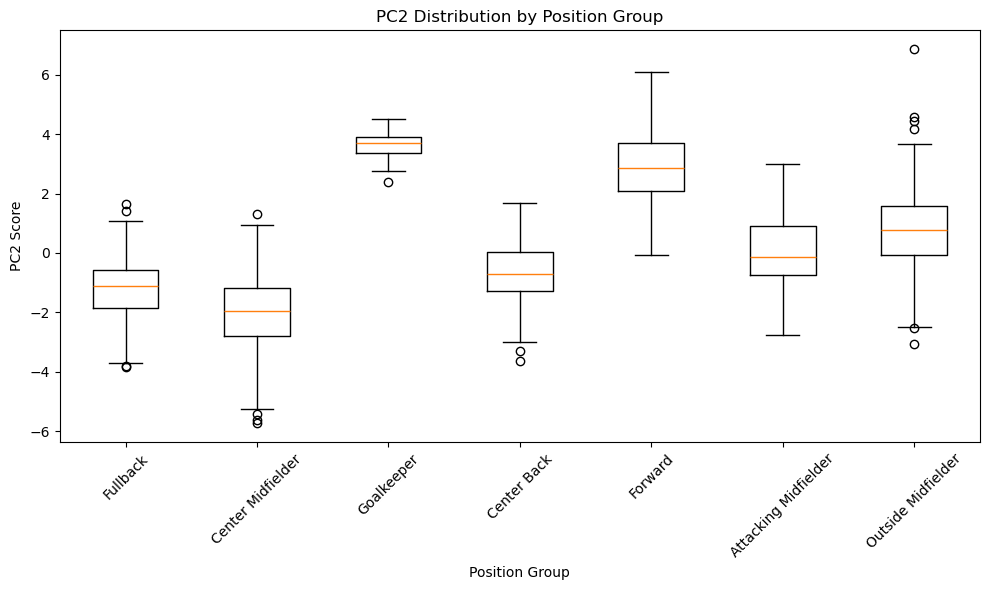

In [58]:
position_groups = scores["position_group"].dropna().unique()

plt.figure(figsize=(10, 6))

data = [
    scores.loc[
        scores["position_group"] == position,
        "PC2"
    ]
    for position in position_groups
]

plt.boxplot(
    data,
    tick_labels=position_groups,
)

plt.xlabel("Position Group")
plt.ylabel("PC2 Score")
plt.title("PC2 Distribution by Position Group")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Loading structure across multiple PCs ##

In [59]:
components_to_show = [
    "PC1",
    "PC2",
    "PC3",
    "PC4",
    "PC5",
    "PC6",
]

loading_matrix = loadings.set_index("feature")[components_to_show]

loading_matrix.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6
feature,,,,,,
goals_per90,0.226,0.240,-0.153,0.279,-0.138,0.027
xG_per90,0.239,0.254,-0.196,0.238,-0.154,-0.000
shots_per90,0.303,0.190,-0.118,0.149,-0.081,-0.027
xA_per90,0.304,0.064,0.165,0.064,-0.084,0.412
shot_assists_per90,0.313,0.018,0.183,0.038,-0.149,0.342
progressive_passes_per90,-0.073,-0.083,0.453,-0.159,-0.187,0.395
passes_completed_per90,0.024,-0.350,0.226,0.347,-0.249,-0.039
pass_completion_pct,0.012,-0.300,-0.030,0.531,-0.035,-0.289
dribbles_attempted_per90,0.332,0.034,0.109,-0.069,0.401,-0.119


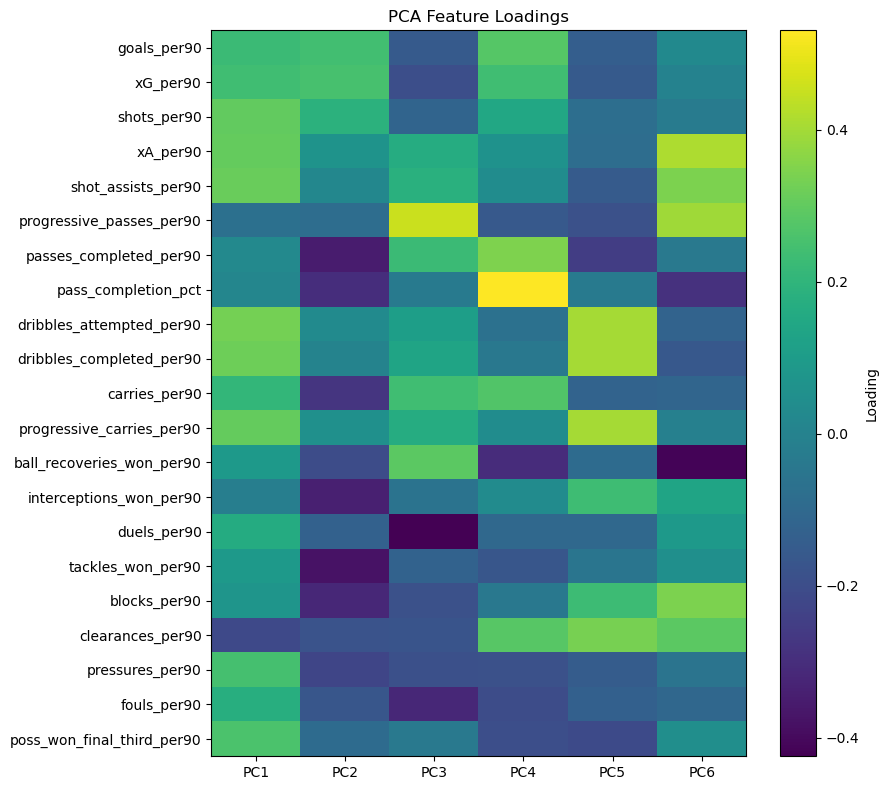

In [60]:
fig, ax = plt.subplots(figsize=(9, 8))

image = ax.imshow(
    loading_matrix.values,
    aspect="auto"
)

ax.set_xticks(range(len(components_to_show)))
ax.set_xticklabels(components_to_show)

ax.set_yticks(range(len(loading_matrix.index)))
ax.set_yticklabels(loading_matrix.index)

plt.colorbar(image, ax=ax, label="Loading")
plt.title("PCA Feature Loadings")

plt.tight_layout()
plt.show()

## Using PCs for Player Similarities ##

In [6]:
pd.set_option('display.max_rows', 300)

test_players = [
    "Carlos Henrique Casimiro",
    "Mesut Özil",
    "Christian Fuchs",
    "Zlatan Ibrahimović",
    "Andros Townsend",
    "Neymar da Silva Santos Junior",
    "Idrissa Gana Gueye",
    "Luca Toni",
    "Ben Foster"
]

component_counts = [6, 7, 8, 10, 12]
n_neighbors = 5

available_players = set(scores["player"].dropna())
selected_players = [player for player in test_players if player in available_players]
missing_players = [player for player in test_players if player not in available_players]

if missing_players:
    print("Players not found in scores:", missing_players)

neighbor_results = []

for player in selected_players:
    for n_components in component_counts:
        pc_columns = [f"PC{i}" for i in range(1, n_components + 1)]
        target_scores = scores.loc[
            scores["player"].eq(player), pc_columns
        ].iloc[0]
        other_players = scores.loc[scores["player"].ne(player)].copy()

        distances = np.linalg.norm(
            other_players[pc_columns].to_numpy() - target_scores.to_numpy(),
            axis=1,
        )
        nearest = other_players.assign(distance=distances).nsmallest(
            n_neighbors, "distance"
        )
        nearest.insert(0, "target", player)
        nearest.insert(1, "n_components", n_components)
        neighbor_results.append(
            nearest[
                [
                    "target",
                    "n_components",
                    "player",
                    "teams",
                    "primary_position",
                    "position_group",
                    "distance",
                ]
            ]
        )

if not neighbor_results:
    raise ValueError("None of the test players were found in scores.")

neighbor_comparison = pd.concat(neighbor_results, ignore_index=True)
display(neighbor_comparison.round({"distance": 3}))

,target,n_components,player,teams,primary_position,position_group,distance
0,Carlos Henrique Casimiro,6,Lucas Pezzini Leiva,[Liverpool],Center Defensive Midfield,Center Midfielder,1.678
1,Carlos Henrique Casimiro,6,Rafidine Abdullah,[Lorient],Left Defensive Midfield,Center Midfielder,1.961
2,Carlos Henrique Casimiro,6,Cheik Ismaël Tioté,[Newcastle United],Right Center Midfield,Center Midfielder,2.023
3,Carlos Henrique Casimiro,6,Sebastián Carlos Cristóforo Pepe,[Sevilla],Left Defensive Midfield,Center Midfielder,2.071
4,Carlos Henrique Casimiro,6,Augusto Matías Fernández,"[Atlético Madrid, Celta Vigo]",Center Defensive Midfield,Center Midfielder,2.255
5,Carlos Henrique Casimiro,7,Cheik Ismaël Tioté,[Newcastle United],Right Center Midfield,Center Midfielder,2.106
6,Carlos Henrique Casimiro,7,Lucas Pezzini Leiva,[Liverpool],Center Defensive Midfield,Center Midfielder,2.195
7,Carlos Henrique Casimiro,7,Sebastián Carlos Cristóforo Pepe,[Sevilla],Left Defensive Midfield,Center Midfielder,2.246
8,Carlos Henrique Casimiro,7,Augusto Matías Fernández,"[Atlético Madrid, Celta Vigo]",Center Defensive Midfield,Center Midfielder,2.495
9,Carlos Henrique Casimiro,7,Pedro Pablo Hernández,[Celta Vigo],Left Center Midfield,Center Midfielder,2.500


## Test ##

In [4]:
import sys
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent
src_dir = project_root / "src"

if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from modeling.pca import (
    fit_pca,
    evaluate_pca_model,
)

In [2]:
standardized_features, player_scores, explained_variance, loadings = fit_pca(27)

Fitted PCA on 1,560 players and 21 features.
Saved PCA artifacts to /Users/TeddyKolios/personal proj/statsbomb/models/pca/2015-2016


In [3]:
component_counts = [6, 7, 8, 10, 12]

results = []

for n_components in component_counts:
    pca_results = evaluate_pca_model(
        player_scores=player_scores,
        standardized_features=standardized_features,
        explained_variance=explained_variance,
        n_components=n_components,
    )

    results.append({
        "n_components": n_components,
        **pca_results,
    })

results_df = pd.DataFrame(results)

NameError: name 'pd' is not defined

In [9]:
results_df

,n_components,cumulative_explained_variance_ratio,trustworthiness,top_k_neighbor_preservation,position_group_consistency
0,4,0.743858,0.961862,0.246923,0.680385
1,5,0.790628,0.974111,0.315256,0.711795
2,6,0.831042,0.985176,0.396795,0.750641
3,7,0.859755,0.990605,0.474487,0.750256
4,8,0.883955,0.993362,0.527564,0.752179
5,9,0.903843,0.995768,0.590641,0.753590


In [10]:
player_scores["position_group"].value_counts()

position_group
Center Midfielder       332
Fullback                300
Center Back             279
Outside Midfielder      265
Forward                 197
Goalkeeper              114
Attacking Midfielder     73
Name: count, dtype: int64

In [11]:
player_scores["position_group"].value_counts(normalize=True)

position_group
Center Midfielder       0.212821
Fullback                0.192308
Center Back             0.178846
Outside Midfielder      0.169872
Forward                 0.126282
Goalkeeper              0.073077
Attacking Midfielder    0.046795
Name: proportion, dtype: float64